# Spotting card fraud

This notebook trains a model that looks at one card payment and gives it a **fraud score**
between 0 and 1. When the score reaches the **alert threshold**, the payment goes to the fraud
team for a check, together with the **top reasons** behind the score. The model learns from
284,807 real, anonymised card payments made by European cardholders in September 2013, of which
492 were fraud.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/snow10100/aie113-projects/blob/main/tracks/fraud/notebook.ipynb)

The full explanation in plain words is in [README.md](README.md) (English) and
[README.ar.md](README.ar.md) (العربية).

## Settings

Everything you might want to change lives here: where the data comes from, where files are
saved, how the time line is split, and the fraud team's rule for alerts.

In [1]:
import json
import os
import time
import urllib.request
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# ULB credit-card fraud data: the original CSV, in the public copy kept for TensorFlow's tutorials
# (same data, if this address ever fails: https://www.openml.org/d/1597)
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
DATA_PATH = "data/creditcard.csv"
MODEL_PATH = "artifacts/fraud_model.joblib"
INFO_PATH = "artifacts/model_info.json"

MODEL_VERSION = "1.0.0"
RANDOM_SEED = 42
TRAIN_SHARE = 0.6        # first 60% of the time line: training
VALID_SHARE = 0.2        # next 20%: choosing the threshold (the last 20% is the test)
MIN_PRECISION = 0.80     # fraud team's rule: at least 8 of every 10 alerts must be real fraud
THRESHOLDS_TO_TRY = [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
AMOUNT_RULE = 1000       # baseline rule: alert on every payment above this amount

plt.rcParams["figure.dpi"] = 90

## Get the data

The original data file (a 150 MB CSV) is downloaded once from the public copy that Google's
TensorFlow team keeps for its tutorials (no account needed) and kept in `data/`. Each row is one
card payment; `Class` is 1 for fraud and 0 for a normal payment.

In [2]:
os.makedirs("data", exist_ok=True)
if not os.path.exists(DATA_PATH):
    print("Downloading", DATA_URL)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH + ".part")
    os.replace(DATA_PATH + ".part", DATA_PATH)

df = pd.read_csv(DATA_PATH)
df["Class"] = df["Class"].astype(int)
print(df.shape)
df.head(3)

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


## A quick look

Fraud is rare: fewer than 2 in every 1,000 payments. So a lazy "model" that always answers
"not fraud" is right 99.8% of the time and still catches no fraud at all. That is why we never
judge this model by accuracy.

In [3]:
n_fraud = df["Class"].sum()
print(f"Payments: {len(df):,}   frauds: {n_fraud}   share of fraud: {n_fraud / len(df):.3%}")
print(f"Always answering 'not fraud' is right {1 - n_fraud / len(df):.2%} of the time, and catches 0 frauds.")
print()
print("Payment amount, normal (0) vs fraud (1):")
df.groupby("Class")["Amount"].describe().round(2)

Payments: 284,807   frauds: 492   share of fraud: 0.173%
Always answering 'not fraud' is right 99.83% of the time, and catches 0 frauds.

Payment amount, normal (0) vs fraud (1):


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


## Build the inputs and split by time

`Time` counts seconds since the first payment in the file, which means nothing for a new
payment, so we turn it into the hour of the day (the file seems to start at midnight: the quiet
hours fall at night). We train on the earliest payments and test on the latest ones, like a bank
that learns from the past and is judged on the future.

In [4]:
df = df.sort_values("Time", kind="stable").reset_index(drop=True)
df["hour"] = (df["Time"] // 3600) % 24
FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount", "hour"]

n = len(df)
train_end = int(n * TRAIN_SHARE)
valid_end = int(n * (TRAIN_SHARE + VALID_SHARE))
train_df = df.iloc[:train_end]
valid_df = df.iloc[train_end:valid_end]
test_df = df.iloc[valid_end:]

X_train, y_train = train_df[FEATURES], train_df["Class"]
X_valid, y_valid = valid_df[FEATURES], valid_df["Class"]
X_test, y_test = test_df[FEATURES], test_df["Class"]

for name, part in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    print(f"{name:5s}: {len(part):7,} payments, {part['Class'].sum():3d} frauds, "
          f"hours {part['Time'].min() / 3600:4.1f} to {part['Time'].max() / 3600:4.1f}")

train: 170,884 payments, 360 frauds, hours  0.0 to 33.4
valid:  56,961 payments,  57 frauds, hours 33.4 to 40.3
test :  56,962 payments,  75 frauds, hours 40.3 to 48.0


## Train the model

We use gradient boosting: it builds a few hundred small decision trees, each one correcting the
mistakes of the trees before it. It learns from all 170,884 training payments in seconds on a
normal CPU, so we do not need to throw away any normal payments.

In [5]:
model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=RANDOM_SEED,
)
start = time.time()
model.fit(X_train, y_train)
print(f"Trained in {time.time() - start:.1f} s")

Trained in 6.6 s


## Choose the alert threshold

A low threshold catches more fraud but bothers more honest customers; a high threshold does the
opposite. We try several thresholds on the validation payments (never on the test payments) and
keep the lowest one where at least 8 of every 10 alerts are real fraud.

Validation payments: 56,961, of which 57 frauds
 threshold  alerts  real frauds in alerts alerts that are fraud frauds caught
      0.01      96                     43                   45%           75%
      0.02      78                     43                   55%           75%
      0.05      63                     42                   67%           74%
      0.10      61                     42                   69%           74%
      0.20      53                     41                   77%           72%
      0.30      52                     41                   79%           72%
      0.40      51                     41                   80%           72%
      0.50      50                     41                   82%           72%
      0.60      49                     40                   82%           70%
      0.70      46                     40                   87%           70%
      0.80      43                     40                   93%           70%
      0.90      

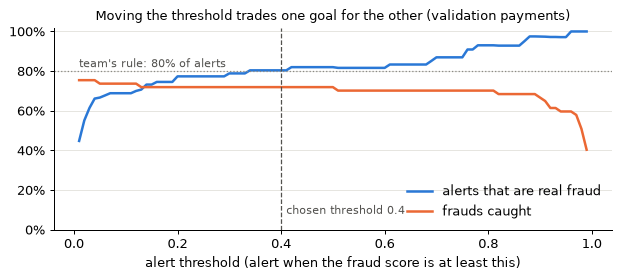

In [6]:
valid_scores = model.predict_proba(X_valid)[:, 1]
y_valid_np = y_valid.values

rows = []
for t in THRESHOLDS_TO_TRY:
    alert = valid_scores >= t
    caught = int((alert & (y_valid_np == 1)).sum())
    rows.append({
        "threshold": t,
        "alerts": int(alert.sum()),
        "real frauds in alerts": caught,
        "alerts that are fraud": caught / alert.sum() if alert.sum() else float("nan"),
        "frauds caught": caught / y_valid_np.sum(),
    })
tradeoff = pd.DataFrame(rows)

meets_rule = tradeoff[tradeoff["alerts that are fraud"] >= MIN_PRECISION]
if meets_rule.empty:
    raise ValueError("No threshold meets the fraud team's rule; try a lower MIN_PRECISION")
THRESHOLD = float(meets_rule["threshold"].min())

print(f"Validation payments: {len(y_valid_np):,}, of which {y_valid_np.sum()} frauds")
print(tradeoff.to_string(index=False, formatters={
    "alerts that are fraud": "{:.0%}".format, "frauds caught": "{:.0%}".format}))
print(f"\nChosen threshold: {THRESHOLD}")

grid = np.linspace(0.01, 0.99, 99)
share_fraud = [((valid_scores >= t) & (y_valid_np == 1)).sum() / max((valid_scores >= t).sum(), 1) for t in grid]
share_caught = [((valid_scores >= t) & (y_valid_np == 1)).sum() / y_valid_np.sum() for t in grid]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(grid, share_fraud, color="#2a78d6", lw=2, label="alerts that are real fraud")
ax.plot(grid, share_caught, color="#eb6834", lw=2, label="frauds caught")
ax.axvline(THRESHOLD, color="#52514e", lw=1, ls="--")
ax.axhline(MIN_PRECISION, color="#8a8984", lw=1, ls=":")
ax.text(0.01, MIN_PRECISION + 0.02, f"team's rule: {MIN_PRECISION:.0%} of alerts", color="#52514e", fontsize=9)
ax.text(THRESHOLD + 0.01, 0.08, f"chosen threshold {THRESHOLD}", color="#52514e", fontsize=9)
ax.set_xlabel("alert threshold (alert when the fraud score is at least this)")
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", color="#e6e5e0")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Moving the threshold trades one goal for the other (validation payments)", fontsize=10)
plt.tight_layout()
plt.show()

## Test: is the model any good?

Now the model meets payments it has never seen: the last 20% of the time line. We compare it
with two simple baselines: always answering "not fraud", and a hand-written rule that alerts on
every payment above 1,000. Look at the last two columns; accuracy looks great for all three.

In [7]:
test_scores = model.predict_proba(X_test)[:, 1]
y_true = y_test.values

candidates = {
    "always 'not fraud'": np.zeros(len(y_true), dtype=bool),
    f"rule: amount > {AMOUNT_RULE}": test_df["Amount"].values > AMOUNT_RULE,
    f"model, threshold {THRESHOLD}": test_scores >= THRESHOLD,
}
results = []
for name, alert in candidates.items():
    caught = int((alert & (y_true == 1)).sum())
    results.append({
        "method": name,
        "accuracy": (alert == (y_true == 1)).mean(),
        "alerts": int(alert.sum()),
        "frauds caught": f"{caught} of {y_true.sum()}",
        "alerts that are fraud": caught / alert.sum() if alert.sum() else float("nan"),
        "share of frauds caught": caught / y_true.sum(),
    })
results = pd.DataFrame(results)
print(results.to_string(index=False, na_rep="no alerts", formatters={
    "accuracy": "{:.2%}".format,
    "alerts that are fraud": "{:.1%}".format,
    "share of frauds caught": "{:.1%}".format,
}))

model_alert = test_scores >= THRESHOLD
false_alarms = int((model_alert & (y_true == 0)).sum())
missed = int((~model_alert & (y_true == 1)).sum())
test_ap = average_precision_score(y_true, test_scores)
fraud_money = test_df["Amount"].values[y_true == 1].sum()
caught_money = test_df["Amount"].values[model_alert & (y_true == 1)].sum()
print(f"\nModel: {false_alarms} false alarms (honest customers bothered), {missed} frauds missed")
print(f"Money in the frauds it caught: {caught_money:,.2f} of {fraud_money:,.2f}")
print(f"Average precision, one number for the whole ranking (1.0 is perfect): {test_ap:.3f}")

              method accuracy  alerts frauds caught alerts that are fraud share of frauds caught
  always 'not fraud'   99.87%       0       0 of 75             no alerts                   0.0%
 rule: amount > 1000   98.99%     503       2 of 75                  0.4%                   2.7%
model, threshold 0.4   99.95%      65      56 of 75                 86.2%                  74.7%

Model: 9 false alarms (honest customers bothered), 19 frauds missed
Money in the frauds it caught: 5,086.09 of 7,729.26
Average precision, one number for the whole ranking (1.0 is perfect): 0.789


## Why did the model say that?

V1 to V28 hide their meaning for privacy, so we cannot say "unusual shop"; we can only say which
numbers drove the score. For one real alert and one false alarm we ask, input by input: *what
if this value were typical?* We set it to its usual value among normal payments and re-score; the bigger the drop,
the stronger the reason.

Payment 229712: amount 1.18, hour 16, fraud score 0.996, real fraud: yes
  - V14 is -9.15 (typical 0.09): if it were typical, the score would fall to 0.061
  - V10 is -4.06 (typical -0.11): if it were typical, the score would fall to 0.085
  - V4 is 6.01 (typical 0.12): if it were typical, the score would fall to 0.944


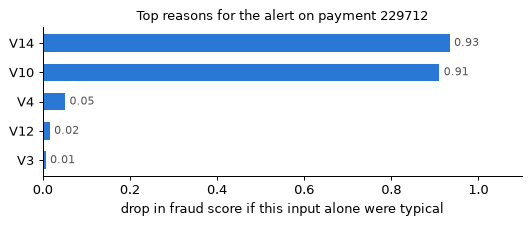


False alarm, payment 228505: amount 0.77, fraud score 0.768, real fraud: no
  - V14 is -7.54 (typical 0.09): if it were typical, the score would fall to 0.001
  - V10 is -2.85 (typical -0.11): if it were typical, the score would fall to 0.001
  - V4 is 3.59 (typical 0.12): if it were typical, the score would fall to 0.428


In [8]:
TYPICAL = train_df.loc[train_df["Class"] == 0, FEATURES].median()


def what_if_typical(model, features_row, typical):
    """Set each input alone to its typical value and see how far the fraud score drops."""
    base_score = model.predict_proba(pd.DataFrame([features_row]))[0, 1]
    variants = pd.DataFrame([features_row] * len(features_row))
    for i, name in enumerate(features_row.index):
        variants.iloc[i, i] = typical[name]
    new_scores = model.predict_proba(variants)[:, 1]
    reasons = pd.DataFrame({
        "value": features_row.values,
        "typical": typical[features_row.index].values,
        "score if typical": new_scores,
        "drop": base_score - new_scores,
    }, index=features_row.index)
    return base_score, reasons.sort_values("drop", ascending=False)


# The first real fraud the model flagged in the test period
caught_ids = test_df.index[model_alert & (y_true == 1)]
example_id = caught_ids[0]
score, reasons = what_if_typical(model, test_df.loc[example_id, FEATURES], TYPICAL)
print(f"Payment {example_id}: amount {test_df.loc[example_id, 'Amount']:.2f}, "
      f"hour {test_df.loc[example_id, 'hour']:.0f}, fraud score {score:.3f}, real fraud: yes")
for name, r in reasons.head(3).iterrows():
    print(f"  - {name} is {r['value']:.2f} (typical {r['typical']:.2f}): "
          f"if it were typical, the score would fall to {r['score if typical']:.3f}")

top = reasons.head(5).iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(top.index, top["drop"], color="#2a78d6", height=0.6)
for y, v in enumerate(top["drop"]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9, color="#52514e")
ax.set_xlim(min(0, top["drop"].min()), 1.1)
ax.set_xlabel("drop in fraud score if this input alone were typical")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Top reasons for the alert on payment {example_id}", fontsize=10)
plt.tight_layout()
plt.show()

# And one false alarm: an honest payment the model flagged
false_alarm_ids = test_df.index[model_alert & (y_true == 0)]
if len(false_alarm_ids) > 0:
    fa_id = false_alarm_ids[0]
    fa_score, fa_reasons = what_if_typical(model, test_df.loc[fa_id, FEATURES], TYPICAL)
    print(f"\nFalse alarm, payment {fa_id}: amount {test_df.loc[fa_id, 'Amount']:.2f}, "
          f"fraud score {fa_score:.3f}, real fraud: no")
    for name, r in fa_reasons.head(3).iterrows():
        print(f"  - {name} is {r['value']:.2f} (typical {r['typical']:.2f}): "
              f"if it were typical, the score would fall to {r['score if typical']:.3f}")
else:
    print("\nNo false alarms in the test period.")

### Which inputs matter most overall?

We shuffle one input at a time on the validation payments, so that it carries no information,
and measure how much worse the model gets at ranking frauds first. A real bank would see named
reasons here, such as "amount far above this customer's usual"; we only see V-numbers.

In [9]:
start = time.time()
perm = permutation_importance(model, X_valid, y_valid, scoring="average_precision",
                              n_repeats=3, random_state=RANDOM_SEED)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
print(f"Drop in average precision when one input is shuffled ({time.time() - start:.0f} s):")
print(importance.head(8).round(3).to_string())

Drop in average precision when one input is shuffled (41 s):
V10    0.244
V14    0.227
V4     0.059
V12    0.024
V17    0.018
V3     0.011
V11    0.010
V1     0.008


## Save the model

A service needs the trained model and a few facts about it: its version, the inputs in the
right order, the threshold, the typical values used for the reasons, and the test numbers. Both
files go into `artifacts/`.

In [10]:
os.makedirs("artifacts", exist_ok=True)
joblib.dump(model, MODEL_PATH)

model_info = {
    "model_version": MODEL_VERSION,
    "model_type": "HistGradientBoostingClassifier",
    "trained_on": datetime.now(timezone.utc).strftime("%Y-%m-%d"),
    "scikit_learn_version": sklearn.__version__,
    "features": FEATURES,
    "threshold": THRESHOLD,
    "threshold_rule": f"lowest tried threshold where at least {MIN_PRECISION:.0%} of validation alerts are real fraud",
    "typical_values": {name: float(value) for name, value in TYPICAL.items()},
    "data": {
        "source": DATA_URL,
        "period": "two days of September 2013 (exact dates not published)",
        "rows": int(len(df)),
        "frauds": int(df["Class"].sum()),
        "train_rows": int(len(train_df)),
        "train_frauds": int(train_df["Class"].sum()),
        "train_hours": [float(train_df["Time"].min() / 3600), float(train_df["Time"].max() / 3600)],
        "valid_rows": int(len(valid_df)),
        "test_rows": int(len(test_df)),
        "test_frauds": int(test_df["Class"].sum()),
    },
    "test_metrics": {
        "alerts": int(model_alert.sum()),
        "frauds_caught": int((model_alert & (y_true == 1)).sum()),
        "precision": float(results.iloc[2]["alerts that are fraud"]),
        "recall": float(results.iloc[2]["share of frauds caught"]),
        "false_alarms": false_alarms,
        "missed_frauds": missed,
        "average_precision": float(test_ap),
        "accuracy": float(results.iloc[2]["accuracy"]),
    },
    "baselines_on_test": {
        "always_not_fraud_accuracy": float(results.iloc[0]["accuracy"]),
        "amount_rule_recall": float(results.iloc[1]["share of frauds caught"]),
        "amount_rule_precision": float(results.iloc[1]["alerts that are fraud"]),
    },
}
with open(INFO_PATH, "w") as f:
    json.dump(model_info, f, indent=2)

print(f"Saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1024:.0f} KB) and {INFO_PATH}")
print(json.dumps(model_info["test_metrics"], indent=2))

Saved artifacts/fraud_model.joblib (597 KB) and artifacts/model_info.json
{
  "alerts": 65,
  "frauds_caught": 56,
  "precision": 0.8615384615384616,
  "recall": 0.7466666666666667,
  "false_alarms": 9,
  "missed_frauds": 19,
  "average_precision": 0.7887467495794763,
  "accuracy": 0.9995084442259752
}


## Score one new payment

This is what the service will do for every payment: load the saved files, build the inputs
exactly as in training, score, decide and explain. The payment below is a real fraud from the
test period, written out the way a request would arrive.

In [11]:
loaded_model = joblib.load("artifacts/fraud_model.joblib")
with open("artifacts/model_info.json") as f:
    info = json.load(f)

new_payment = {
    "Time": 154278.0, "Amount": 1504.93,
    "V1": -1.60021129907252, "V2": -3.48813018118561, "V3": -6.45930280667571, "V4": 3.24681566349703,
    "V5": -1.61460769860713, "V6": -1.26037454854632, "V7": 0.288223321921388, "V8": -0.0489639910109505,
    "V9": -0.734974617920653, "V10": -4.44148408070017, "V11": 2.94437484242405, "V12": -3.80546898374331,
    "V13": -2.10222683492697, "V14": -6.1061832734711, "V15": -0.641736399701777, "V16": -1.55596289626148,
    "V17": -2.08406707082134, "V18": 0.394247352869229, "V19": 0.0833797227600835, "V20": 3.18935489592753,
    "V21": 1.19117480721903, "V22": -0.96714144500067, "V23": -1.46342052446637, "V24": -0.624230851495284,
    "V25": -0.176461532068143, "V26": 0.400348351070197, "V27": 0.152946864261687, "V28": 0.477774924576796,
}

# Same input steps as in training
features = dict(new_payment)
features["hour"] = (features["Time"] // 3600) % 24
row = pd.DataFrame([features])[info["features"]]

score = loaded_model.predict_proba(row)[0, 1]
decision = "ALERT: send to the fraud team" if score >= info["threshold"] else "allow"
print(f"Fraud score {score:.3f} (threshold {info['threshold']}): {decision}")

_, reasons = what_if_typical(loaded_model, row.iloc[0], pd.Series(info["typical_values"]))
print("Top reasons:")
for name, r in reasons.head(3).iterrows():
    print(f"  - {name} is {r['value']:.2f} (typical {r['typical']:.2f}): "
          f"if it were typical, the score would fall to {r['score if typical']:.3f}")

Fraud score 0.999 (threshold 0.4): ALERT: send to the fraud team
Top reasons:
  - V14 is -6.11 (typical 0.09): if it were typical, the score would fall to 0.149
  - V10 is -4.44 (typical -0.11): if it were typical, the score would fall to 0.278
  - V4 is 3.25 (typical 0.12): if it were typical, the score would fall to 0.983


## Your project starts here

1. **Clean architecture**: split this notebook into a domain (payment, score, threshold rule,
   reasons), services and adapters, with settings in one place.
2. **FastAPI endpoint**: send one payment, get a fraud score, a decision and the top reasons.
3. **Container**: package the service with Docker so it runs the same everywhere.
4. **Tests**: prove the inputs, the decision rule, the reasons and the model's quality.
5. **GitHub Actions**: run the checks and build the image on every change.
6. **Secrets**: handle a real-looking secret (an alerting webhook token) the modern way.
7. **Optional front end**: a small Vite + React page for the fraud team.

Follow [GUIDE.md](../../GUIDE.md) stage by stage.